# Creating a ground truth by using label transfer from one annotated slide to the other slides. 

In [1]:
from pathlib import Path
import os
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
from sklearn.neighbors import KNeighborsClassifier
import gc

%load_ext autoreload
%autoreload 2

sys.path.insert(0, str(Path("..").resolve()))
from functions import plotting as pl
from functions import label_transfer as lt

In [3]:
basedir = Path("../data")
dir_uni =  "01_preprocessing/unimodel/metadata"
samples = ["CRC_P1", "CRC_P2", "CRC_P5", "Normal_P3", "Normal_P5", "CRC_P6_5mm", "CRC_P11mm", "CRC_P11mm_2_cut"]

def label_transfer_dir(sample_id):
    """data/{sample}/02_baselines/label_transfer -- matches functions/label_transfer.py's OUT_DIR_TEMPLATE."""
    return basedir / sample_id / "02_baselines/label_transfer"


### Patch-level label transfer

Runs `functions/label_transfer.py` -- two classifiers (UNI image embeddings, and
aggregated-transcriptomics-per-patch) trained on the CRC_P2 ground truth and
applied to every other sample. Both the reference and every target are sourced
from `filtered_WSI_patch_embeddings.h5ad`, so background/no-tissue patches
(identified via the leiden-cluster filtering in `02_downstream_analysis_uni.ipynb`)
are excluded from training and prediction.

In [ ]:
import importlib
from functions import label_transfer as lt

importlib.reload(lt)  # pick up any edits without restarting the kernel

# min_compound_label_count: None -> collapse every tissuetype to its dominant
#   component (6 base classes). An int (e.g. 100) instead keeps common
#   border-region labels (e.g. "Veins_Neoplasm") as their own class.
# neoplasm_prior_weight_on_normal: None disables the prior entirely. 0.0 hard-masks
#   Neoplasm on "Normal_*" slides; e.g. 0.1 soft-downweights it instead.
# model_type: "mlp" (default, small GPU neural net) or "knn" (sklearn k-NN,
#   CPU, no training loop -- simpler, handles rare classes naturally).
lt.main(
    min_compound_label_count=50,
    neoplasm_prior_weight_on_normal=0.1,
    model_type="mlp",
)

In [ ]:
# Merge every target sample's predictions into one combined AnnData:
# data/combined/02_baselines/label_transfer/combined_patch_predictions.h5ad
# Uses discover_target_samples() so this always matches exactly what lt.main()
# just produced (CRC_P2 is the reference, not a prediction target, so it's
# excluded here too, same as in main()).
from functions.merge import merge_anndatas

merged_predictions = merge_anndatas(
    lt.discover_target_samples(),
    "{basedir}/{sample}/02_baselines/label_transfer/{filename}",
    "{sample}_patch_predictions.h5ad",
    basedir,
    obs_name_mode="unique",
    per_sample_pca_key=None,
)

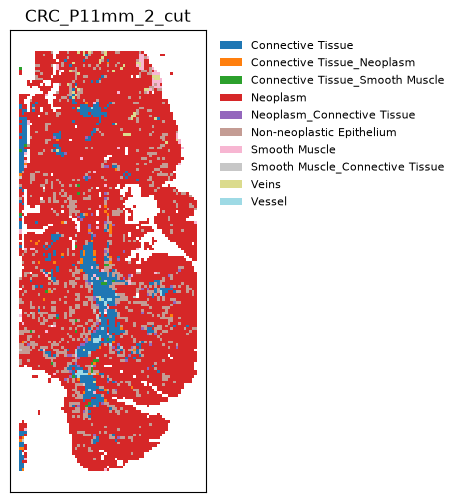

In [4]:
# plot one sample based on patch-level label transfer

sample_id = samples[7]  # swap for any sample_id you want to inspect or set string like "CRC_P1"
result_dir = label_transfer_dir(sample_id)
if sample_id == "CRC_P2":
    adata_sample = sc.read_h5ad(result_dir / f"{sample_id}_with_annotation.h5ad")
else:
    adata_sample = sc.read_h5ad(result_dir / f"{sample_id}_patch_predictions.h5ad")


# TODO: optionally fix spatial key, so spatial information can also be somewhere else
pl.plot_spatial_labels(
    adata_sample,
    spatial_key="spatial",
    label_key="predicted_tissuetype_image",  # or "predicted_tissuetype_transcriptomics"
    title=sample_id,
    mode="patch",
)
plt.show()

/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


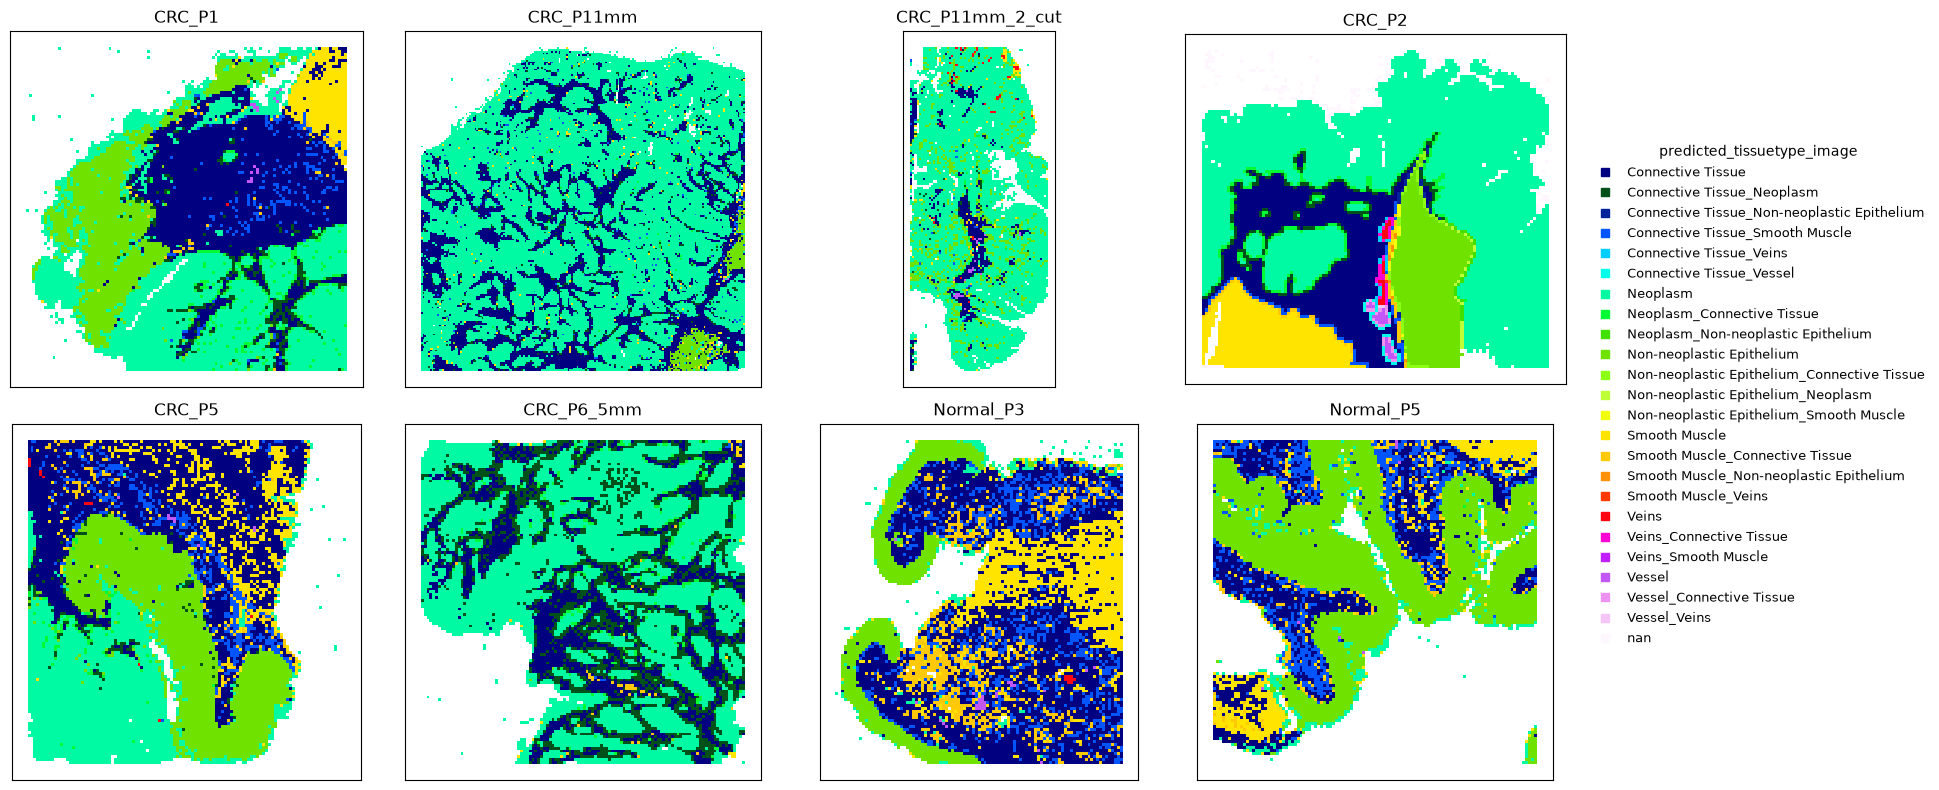

In [5]:
#  plot all samples based on patch-level label transfer
obs_list, spatial_list = [], []

for sample_id in samples:
    if sample_id == "CRC_P2":
        # CRC_P2 is the label-transfer reference, not a target -- no _patch_predictions.h5ad.
        # Use its own real per-patch ground truth instead, under the same column name.
        a = sc.read_h5ad(basedir / sample_id / dir_uni / "filtered_WSI_patch_embeddings.h5ad", backed="r")
        obs = a.obs.copy()
        obs["predicted_tissuetype_image"] = obs["tissuetype"]
    else:
        out_file = label_transfer_dir(sample_id) / f"{sample_id}_patch_predictions.h5ad"
        if not out_file.exists():
            continue
        a = sc.read_h5ad(out_file, backed="r")
        obs = a.obs.copy()

    obs["Slide_ID"] = sample_id
    obs_list.append(obs)
    spatial_list.append(np.asarray(a.obsm["spatial"]))
    del a

obs_all = pd.concat(obs_list, axis=0, ignore_index=True)
spatial_all = np.vstack(spatial_list)

# Collapse compound labels ("Most-dominant_2nd_3rd...") to just their top 2 dominant
# components, so e.g. "Smooth Muscle_Veins" and "Smooth Muscle_Veins_Vessel" merge.
obs_all["predicted_tissuetype_image"] = obs_all["predicted_tissuetype_image"].astype(str).str.split("_").str[:2].str.join("_")

# dummy 1-column X: we only need obs + obsm for plotting
adata_all = ad.AnnData(X=np.zeros((obs_all.shape[0], 1)), obs=obs_all)
adata_all.obsm["spatial"] = spatial_all
adata_all.obs["Slide_ID"] = adata_all.obs["Slide_ID"].astype("category")

pl.plot_spatial_labels_grid(
    adata_all,
    slide_key="Slide_ID",
    spatial_key="spatial",
    label_key="predicted_tissuetype_image",  # swap to "predicted_tissuetype_transcriptomics" to compare
    ncols=4,
    mode="patch",
)
plt.show()

#### Label transfer, with Harmony batch correction (comparison run)
Same reference/target label transfer as above, but the image classifier is trained and applied on a joint PCA + Harmony-corrected embedding (keyed on `Slide_ID`) instead of the raw UNI embedding, to check whether removing slide-to-slide batch effects improves the image-based predictions. This is an *additional* run for comparison: outputs go to `{sample}_patch_predictions_harmony.h5ad` / `combined_patch_predictions_harmony.h5ad`, alongside (not replacing) the originals. Code + resulting AnnData objects to be cleaned up later once we decide which approach to keep.

In [ ]:
import importlib
from functions import label_transfer as lt

importlib.reload(lt)  # pick up any edits without restarting the kernel

# Same knobs as the raw run above, but use_harmony=True: trains/predicts the image
# classifier on a joint PCA + Harmony-corrected embedding (keyed on Slide_ID) instead
# of raw UNI .X. Writes to "{sample}_patch_predictions_harmony.h5ad" (raw outputs
# untouched), so both can be compared side by side.
lt.main(
    min_compound_label_count=50,
    neoplasm_prior_weight_on_normal=0.1,
    model_type="mlp",
    use_harmony=True,
)

In [ ]:
# Merge the harmony-corrected predictions into one combined AnnData:
# data/combined/02_baselines/label_transfer/combined_patch_predictions_harmony.h5ad
from functions.merge import merge_anndatas

merged_predictions_harmony = merge_anndatas(
    lt.discover_target_samples(),
    "{basedir}/{sample}/02_baselines/label_transfer/{filename}",
    "{sample}_patch_predictions_harmony.h5ad",
    basedir,
    obs_name_mode="unique",
    per_sample_pca_key=None,
)

In [ ]:
#  plot all samples based on patch-level label transfer
obs_list, spatial_list = [], []

for sample_id in samples:
    if sample_id == "CRC_P2":
        # CRC_P2 is the label-transfer reference, not a target -- no _patch_predictions_harmony.h5ad.
        # Use its own real per-patch ground truth instead (same for both the raw and harmony grids).
        a = sc.read_h5ad(basedir / sample_id / dir_uni / "filtered_WSI_patch_embeddings.h5ad", backed="r")
        obs = a.obs.copy()
        obs["predicted_tissuetype_image"] = obs["tissuetype"]
    else:
        out_file = label_transfer_dir(sample_id) / f"{sample_id}_patch_predictions_harmony.h5ad"
        if not out_file.exists():
            continue
        a = sc.read_h5ad(out_file, backed="r")
        obs = a.obs.copy()

    obs["Slide_ID"] = sample_id
    obs_list.append(obs)
    spatial_list.append(np.asarray(a.obsm["spatial"]))
    del a

obs_all = pd.concat(obs_list, axis=0, ignore_index=True)
spatial_all = np.vstack(spatial_list)

# Collapse compound labels ("Most-dominant_2nd_3rd...") to just their top 2 dominant
# components, so e.g. "Smooth Muscle_Veins" and "Smooth Muscle_Veins_Vessel" merge.
obs_all["predicted_tissuetype_image"] = obs_all["predicted_tissuetype_image"].astype(str).str.split("_").str[:2].str.join("_")

# dummy 1-column X: we only need obs + obsm for plotting
adata_all = ad.AnnData(X=np.zeros((obs_all.shape[0], 1)), obs=obs_all)
adata_all.obsm["spatial"] = spatial_all
adata_all.obs["Slide_ID"] = adata_all.obs["Slide_ID"].astype("category")

pl.plot_spatial_labels_grid(
    adata_all,
    slide_key="Slide_ID",
    spatial_key="spatial",
    label_key="predicted_tissuetype_image",  
    ncols=4,
    mode="patch",
)
plt.show()

# Histology
This section covers a few single-omics evaluation. 
1. **Evaluation of the preprocessing steps**: This section focusses on illustrating the preprocessing steps done on histology. This gives as an overview over parameters such as patch count and predicted disease status but also label distribution and more.    
2. We will also evaluate the **clustering performed on the PCA results** of the patch embeddings, independent of the ground truth. Here, we do not have labels for the clusters.

#### Evaluation of preprocessing steps
This first cell gives us an overview over some basic information such as patch count and disease status prediction of the label transfer.

In [ ]:
meta = ad.read_h5ad(basedir / "combined" / dir_uni / "WSI_patch_metadata.h5ad", backed="r").obs
filt = ad.read_h5ad(basedir / "combined" / dir_uni / "filtered_WSI_patch_embeddings.h5ad", backed="r").obs
pred = sc.read_h5ad(basedir / "combined" / "02_baselines/label_transfer/combined_patch_predictions_harmony.h5ad", backed="r").obs

corners = meta.groupby("Slide_ID")[["X", "Y"]].agg(["min", "max"]).astype(int)
corners.columns = ["x_min", "x_max", "y_min", "y_max"]

summary = corners.reindex(samples)
summary.index.name = "Slide_ID"
summary["n_patches_total"] = meta["Slide_ID"].value_counts()
summary["n_patches_filtered"] = filt["Slide_ID"].value_counts()
summary["status_original"] = summary.index.map(lt.get_disease_status)
summary["predicted_diseased_tissue_pct"] = 100 * pred["predicted_tissuetype_image"].str.contains("Neoplasm").groupby(pred["Slide_ID"]).mean()

summary

Now, we take a closer look at the label distribution per slide. 
Note, that this is based purely on the annotation labels provided in the ground truth. Possible further labels are only evaluated later, when incorporating the results from the autoencoder. 

In [ ]:
crc_p2_annotation = sc.read_h5ad(label_transfer_dir("CRC_P2") / "CRC_P2_with_annotation.h5ad", backed="r").obs["annotation"]
crc_p2_dist = crc_p2_annotation.value_counts(normalize=True) * 100
crc_p2_dist.name = "CRC_P2"

label_dist = pd.crosstab(pred["Slide_ID"], pred["predicted_tissuetype_image"], normalize="index") * 100
label_dist = pd.concat([label_dist, crc_p2_dist.to_frame().T]).reindex(samples)

ax = label_dist.plot(kind="bar", stacked=True, figsize=(10, 6), colormap="tab20")
ax.set_ylabel("% of patches (CRC_P2: % of annotated bins, ground truth)")
ax.set_xlabel("Slide_ID")
ax.set_title("Tissue-type label distribution per slide")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="label")
plt.tight_layout()
plt.show()

#### 2nd ground truth: Leiden clustering on UNI PCA

We will perform three types of leiden clustering:
1. In the first step, we will perform leiden clustering on PCA values of UNI2-h patch embeddings separately for each slide.
2. During the second step, we perfom leiden clustering over all slides combined. 

**Step 1: Leiden per Sample**
As a first step, we perform leiden *per sample*, so not over all samples at once. 

In [ ]:
sample = "CRC_P2"
adata_single = sc.read_h5ad(basedir / sample / dir_uni / "filtered_WSI_patch_embeddings.h5ad")
adata_combined = sc.read_h5ad(basedir / "combined" / dir_uni / "filtered_WSI_patch_embeddings.h5ad")

We now plot the leiden clustering result next to the result of the label transferred ground truth for the same slide next to each other.
By changing the parameter `sample` in the cell above, you can change the slide you see below.

In [ ]:
adata_single.obs["tissuetype_top2"] = adata_single.obs["tissuetype"].astype(str).str.split("_").str[:2].str.join("_")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
pl.plot_spatial_labels(
    adata_single,
    spatial_key="spatial",
    label_key="leiden_0.5",
    title=f"{sample} - leiden_0.5",
    mode="patch",
    ax=axes[0],
)
pl.plot_spatial_labels(
    adata_single,
    spatial_key="spatial",
    label_key="tissuetype_top2",
    title=f"{sample} - ground truth (top 2 dominant labels)",
    mode="patch",
    ax=axes[1],
)
plt.tight_layout()
plt.show()

To compare the results, we test the ARI on all slides.
We perform two comparisons: 
- `ARI_full` — the full compound label as basis: tissuetype (real ground truth) for CRC_P2, predicted_tissuetype_image (label-transfer prediction) for the other six slides.
- `ARI_top2` — same basis labels, but collapsed to only the two most dominant _-joined components first (reusing the same top-2 truncation logic from the previous cell), so triple/quadruple compound labels merge into their top-2 equivalent before scoring.

In [ ]:
from sklearn.metrics import adjusted_rand_score

def get_basis_and_leiden(sample_id):
    """Ground truth (CRC_P2) or label-transfer prediction (other slides) vs. leiden_0.5, same patch order."""
    if sample_id == "CRC_P2":
        obs = sc.read_h5ad(basedir / sample_id / dir_uni / "filtered_WSI_patch_embeddings.h5ad", backed="r").obs
        basis = obs["tissuetype"]
    else:
        obs = sc.read_h5ad(label_transfer_dir(sample_id) / f"{sample_id}_patch_predictions.h5ad", backed="r").obs
        basis = obs["predicted_tissuetype_image"]
    return basis.astype(str), obs["leiden_0.5"]

def top2(labels):
    return labels.str.split("_").str[:2].str.join("_")

ari_rows = []
for sample_id in samples:
    basis, leiden = get_basis_and_leiden(sample_id)
    ari_rows.append({
        "Slide_ID": sample_id,
        "ARI_full": adjusted_rand_score(basis, leiden),
        "ARI_top2": adjusted_rand_score(top2(basis), leiden),
    })

ari_df = pd.DataFrame(ari_rows).set_index("Slide_ID")
ari_df

For comparative overview, we now plot all images for PCA=50 and leiden resolution=0.2.

**2nd step: Leiden WITHOUT batch correction over all samples**

In [ ]:
# run PCA, neighbor graph and leiden on all samples at once
sc.pp.pca(adata_combined, n_comps=50)
sc.pp.neighbors(adata_combined)          
sc.tl.leiden(
    adata_combined,
    resolution=0.2,
    key_added="leiden_0.2_joint_no_batch_correct",
    flavor="igraph",
    n_iterations=2,
    directed=False,
)

pl.plot_spatial_labels_grid(
    adata_combined,
    slide_key="Slide_ID",
    spatial_key="spatial",
    label_key="leiden_0.2_joint_no_batch_correct", 
    ncols=4,
    mode="patch",
)
plt.show()

**3rd: Leiden WITH batch correction** 

In [ ]:
# Issue:
# here, Slide_ID (the thing you'd batch-correct on) is in exact 1:1 correspondence with the label you're trying to predict. 
# Every slide has exactly one disease status — no two slides share a condition the way replicate samples usually do in scRNA-seq batch correction. 
# So "correct for Slide_ID" and "remove the disease signal" are mathematically the same operation here. Harmony (or any batch-correction method keyed on Slide_ID) 
# can't distinguish "this is slide-to-slide technical variation" from "this is the biological CRC-vs-Normal difference," 
# because nothing in the data lets it tell those apart — they're perfectly confounded.

In [ ]:
import harmonypy

# Harmony-correct the joint PCA, keyed on Slide_ID, then re-cluster on the corrected representation.
# NOTE: bypassing sce.pp.harmony_integrate -- it does `Z_corr.T`, which was correct for
# harmonypy<2.0 (Z_corr was (n_pcs, n_obs)) but double-transposes with harmonypy>=2.0,
# where Z_corr is already (n_obs, n_pcs).
harmony_out = harmonypy.run_harmony(adata_combined.obsm["X_pca"].astype(np.float64), adata_combined.obs, "Slide_ID")
adata_combined.obsm["X_pca_harmony"] = harmony_out.Z_corr

sc.pp.neighbors(adata_combined, use_rep="X_pca_harmony")
sc.tl.leiden(
    adata_combined,
    resolution=0.2,
    key_added="leiden_0.2_harmony",
    flavor="igraph",
    n_iterations=2,
    directed=False,
)

pl.plot_spatial_labels_grid(
    adata_combined,
    slide_key="Slide_ID",
    spatial_key="spatial",
    label_key="leiden_0.2_harmony",
    ncols=4,
    mode="patch",
)
plt.show()

**ARI comparison: ground truth vs. three clustering modes, purely on patches**
Basis (ground truth): `CRC_P2`'s real `tissuetype` (already sitting in `adata_combined.obs`, no separate load needed), and the raw label-transfer `predicted_tissuetype_image` (from `combined_patch_predictions.h5ad`, *not* the harmony one) for the other six slides -- same convention as the earlier per-sample ARI cell above.
Modes compared, all already computed above (nothing recomputed here): (1) `leiden_0.5` -- per-sample leiden, saved on disk in each sample's own file; (2) `leiden_0.2_joint_no_batch_correct` -- joint PCA + leiden across all 7 slides, no batch correction, lives in `adata_combined.obs` from the "2nd step" cell; (3) `leiden_0.2_harmony` -- same but Harmony-corrected, from the cell just above. Modes 2/3 only exist in-session, so those two cells must have run first.

In [ ]:
from sklearn.metrics import adjusted_rand_score

required = ["leiden_0.2_joint_no_batch_correct", "leiden_0.2_harmony"]
missing = [c for c in required if c not in adata_combined.obs]
if missing:
    raise RuntimeError(f"adata_combined.obs missing {missing} -- run the '2nd step' and '3rd' leiden cells above first.")

pred_raw = sc.read_h5ad(basedir / "combined/02_baselines/label_transfer/combined_patch_predictions.h5ad", backed="r").obs

def get_basis(sample_id):
    """Ground truth (CRC_P2) or raw label-transfer prediction (other slides), indexed by Patch_ID."""
    if sample_id == "CRC_P2":
        sub = adata_combined.obs.loc[adata_combined.obs["Slide_ID"] == sample_id, ["Patch_ID", "tissuetype"]]
        return sub.set_index("Patch_ID")["tissuetype"].astype(str)
    sub = pred_raw.loc[pred_raw["Slide_ID"] == sample_id, ["Patch_ID", "predicted_tissuetype_image"]]
    return sub.set_index("Patch_ID")["predicted_tissuetype_image"].astype(str)

def get_leiden(sample_id, key, per_sample_file=False):
    """key from adata_combined.obs (joint modes), or from each sample's own file (per-sample mode)."""
    if per_sample_file:
        if sample_id == "CRC_P2":
            obs = sc.read_h5ad(basedir / sample_id / dir_uni / "filtered_WSI_patch_embeddings.h5ad", backed="r").obs
        else:
            obs = sc.read_h5ad(label_transfer_dir(sample_id) / f"{sample_id}_patch_predictions.h5ad", backed="r").obs
        return obs.set_index("Patch_ID")[key]
    sub = adata_combined.obs.loc[adata_combined.obs["Slide_ID"] == sample_id, ["Patch_ID", key]]
    return sub.set_index("Patch_ID")[key]

def ari_vs_basis(basis, leiden):
    common = basis.index.intersection(leiden.index)
    return adjusted_rand_score(basis.loc[common], leiden.loc[common])

rows = []
for sample_id in samples:
    basis = get_basis(sample_id)
    rows.append({
        "Slide_ID": sample_id,
        "ARI_per_sample_leiden": ari_vs_basis(basis, get_leiden(sample_id, "leiden_0.5", per_sample_file=True)),
        "ARI_joint_no_batch_correct": ari_vs_basis(basis, get_leiden(sample_id, "leiden_0.2_joint_no_batch_correct")),
        "ARI_joint_harmony": ari_vs_basis(basis, get_leiden(sample_id, "leiden_0.2_harmony")),
    })

ari_modes_df = pd.DataFrame(rows).set_index("Slide_ID")
ari_modes_df

**One slide, four clustering results side by side**
Same idea as the joint-leiden grid plots above (one label, all slides), just transposed: one slide (`sample`, set in the "Step 1: Leiden per Sample" cell), four labels -- ground truth/label transfer, per-sample leiden, joint leiden (no batch correction), joint leiden + Harmony. All four columns already live in `adata_combined.obs` (plus `pred_raw` for the label-transfer basis on non-`CRC_P2` slides, reused from the ARI cell above), so nothing is recomputed here.

In [ ]:
plot_sample = sample  # reuse the slide selected in the "Step 1: Leiden per Sample" cell above

mask = adata_combined.obs["Slide_ID"] == plot_sample
sub = adata_combined.obs.loc[mask].copy()
sub_spatial = np.asarray(adata_combined.obsm["spatial"])[mask.to_numpy()]

if plot_sample == "CRC_P2":
    sub["ground_truth"] = sub["tissuetype"]
else:
    basis = pred_raw.loc[pred_raw["Slide_ID"] == plot_sample, ["Patch_ID", "predicted_tissuetype_image"]].set_index("Patch_ID")["predicted_tissuetype_image"]
    sub["ground_truth"] = sub["Patch_ID"].map(basis)
sub["ground_truth"] = sub["ground_truth"].astype(str).str.split("_").str[:2].str.join("_")

plot_adata = ad.AnnData(X=np.zeros((sub.shape[0], 1)), obs=sub)
plot_adata.obsm["spatial"] = sub_spatial

fig, axes = plt.subplots(1, 4, figsize=(22, 6))
pl.plot_spatial_labels(plot_adata, spatial_key="spatial", label_key="ground_truth", title=f"{plot_sample} - ground truth / label transfer", mode="patch", ax=axes[0])
pl.plot_spatial_labels(plot_adata, spatial_key="spatial", label_key="leiden_0.5", title=f"{plot_sample} - per-sample leiden", mode="patch", ax=axes[1])
pl.plot_spatial_labels(plot_adata, spatial_key="spatial", label_key="leiden_0.2_joint_no_batch_correct", title=f"{plot_sample} - joint leiden (no batch correct)", mode="patch", ax=axes[2])
pl.plot_spatial_labels(plot_adata, spatial_key="spatial", label_key="leiden_0.2_harmony", title=f"{plot_sample} - joint leiden + harmony", mode="patch", ax=axes[3])
plt.tight_layout()
plt.show()

**8µm ground truth, for comparing against cell-level (autoencoder) clustering**
The autoencoder's leiden clusters are defined per cell (nucleus), not per bin or patch, so the patch-level ground truth used above doesn't line up with it directly. This aggregates `CRC_P2`'s real bin-level annotation up to an 8µm grid -- an exact 4x4 block of 2µm bins per grid cell (Visium HD's bin grids are hierarchically nested), majority vote per cell -- then assigns every nucleus the label of its nearest 8µm grid cell by centroid distance. No new h5ad: the result is stored as a new `tissuetype_008um` column directly in `CRC_P2`'s existing `count_area_filtered_adata.h5ad`, overwritten in place (same pattern `CustomBinning.ipynb` already uses when it adds `Patch_ID` to that file). Ready to plug into an ARI comparison against the autoencoder's cell-level leiden clusters.


In [ ]:
grid_gt_008um = lt.aggregate_bin_annotation_to_grid(reference_sample="CRC_P2", group_size=4)  # 4 x 2um = 8um
grid_gt_008um["annotation"].value_counts().head(10)


In [ ]:
# Label transfer at 8um-grid resolution, mirroring the patch-level pipeline above:
# image classifier on aggregated raw-token features (aggregate_tokens_to_grid),
# transcriptomics classifier on SpaceRanger's own native square_008um binning
# (load_grid_bin_counts -- already properly aggregated, no manual bin summation
# needed). Writes "{sample}_grid_predictions.h5ad" per target sample, same pattern
# as "{sample}_patch_predictions.h5ad" above.
importlib.reload(lt)
lt.main_grid(group_size=4)  # 4 x 2um = 8um


In [ ]:
# Assign every slide's own cells to their nearest 8um grid cell's label -- ground
# truth for CRC_P2 (grid_gt_008um, above), predicted (image-based) grid label for
# the other six (lt.main_grid()'s output, above). Stored under the same column
# name (tissuetype_008um) in each slide's own count_area_filtered_adata.h5ad, so
# a later ARI cell can read it directly per slide, same as the ground-truth-vs-
# clustering cells earlier in this notebook.
# NOTE: CRC_P5, Normal_P3, Normal_P5 have no local square_008um output (only
# square_002um), so lt.main_grid() skipped them -- no _grid_predictions.h5ad
# exists for those three, and they're skipped here too.
dir_custom_binning = "01_preprocessing/cell_seg_stardist/002um/custom_binning"

for sample_id in samples:
    cells_path = basedir / sample_id / dir_custom_binning / "count_area_filtered_adata.h5ad"
    cells = sc.read_h5ad(cells_path)

    if sample_id == "CRC_P2":
        labels = lt.assign_nearest_grid_label(cells.obsm["spatial"], grid_gt_008um, label_col="annotation")
    else:
        pred_path = basedir / sample_id / "02_baselines/label_transfer" / f"{sample_id}_grid_predictions.h5ad"
        if not pred_path.exists():
            print(f"{sample_id}: no _grid_predictions.h5ad (no local square_008um output) -- skipping.")
            continue
        pred = sc.read_h5ad(pred_path, backed="r")
        grid_pred = pd.DataFrame({
            "pxl_col": pred.obsm["spatial"][:, 0],
            "pxl_row": pred.obsm["spatial"][:, 1],
            "predicted_tissuetype_grid_image": pred.obs["predicted_tissuetype_grid_image"].to_numpy(),
        })
        labels = lt.assign_nearest_grid_label(
            cells.obsm["spatial"], grid_pred, label_col="predicted_tissuetype_grid_image"
        )

    cells.obs["tissuetype_008um"] = labels
    cells.write_h5ad(cells_path)
    print(f"{sample_id}: {cells.obs['tissuetype_008um'].value_counts().to_dict()}")


# Transcriptomics

### 1st ground truth: assign labels to cells based on bin labeling
<span style="color:red">Check in eval: influence of lower UMI!!!.</span>

In this first part of the evaluation, we check the preprocessing of the transcriptomics. 
As a first step, we 

In [ ]:
# Plot UMI count distribution for all slides before filtering them out (check CustomBinning.ipynb for the right anndata to load)
import pickle
import geopandas as gpd
from shapely.geometry import Polygon

dir_custom_binning = "01_preprocessing/cell_seg_stardist/002um/custom_binning"
dir_cellseg = "01_preprocessing/cell_seg_stardist/002um"
UMI_CUTOFF = 50   # matches the actual filter applied in CustomBinning.ipynb (total_counts > 50)
AREA_CUTOFF = 500  # matches the actual filter applied in CustomBinning.ipynb (area < 500 px^2)

# nuclei_grouped_UMI_count.h5ad has no total_counts/area saved -- both need to be
# computed here, same as CustomBinning.ipynb does. Area only exists via the raw
# StarDist polygons (polys_FullSection.pckl), joined onto the UMI-count population by id.
qc_by_slide = {}
for sample_id in samples:
    adata = sc.read_h5ad(basedir / sample_id / dir_custom_binning / "nuclei_grouped_UMI_count.h5ad")
    sc.pp.calculate_qc_metrics(adata, percent_top=None, inplace=True)

    with open(basedir / sample_id / dir_cellseg / "polys_FullSection.pckl", "rb") as f:
        polys = pickle.load(f)
    geometries = [Polygon([(y, x) for x, y in zip(c[0], c[1])]) for c in polys["coord"]]
    gdf = gpd.GeoDataFrame({"id": [f"ID_{i+1}" for i in range(len(geometries))], "area": gpd.GeoSeries(geometries).area})

    qc_by_slide[sample_id] = adata.obs[["id", "total_counts", "n_genes_by_counts"]].merge(gdf, on="id", how="left")
    del adata, polys, geometries, gdf
    gc.collect()

pl.plot_distribution_grid(
    {s: df["total_counts"].to_numpy() for s, df in qc_by_slide.items()},
    xlabel="Total UMI counts per nucleus",
    title="UMI count distribution per slide (before filtering)",
    cutoff=UMI_CUTOFF,
    log_x=True,
)
plt.show()


In [ ]:
# Plot cell size distribution for all slides before filtering them out (check CustomBinning.ipynb for the right anndata to load)
pl.plot_distribution_grid(
    {s: df["area"].to_numpy() for s, df in qc_by_slide.items()},
    xlabel="Nucleus area (px²)",
    title="Nucleus area distribution per slide (before filtering)",
    cutoff=AREA_CUTOFF,
    log_x=True,
)
plt.show()


In [ ]:
# plot cell count per slide:
# 1. total before filtering
# 2. removed through UMI filter
# 3. removed through size filter
# 4. total left
funnel_rows = []
for sample_id, df in qc_by_slide.items():
    fail_umi = df["total_counts"] <= UMI_CUTOFF
    fail_area = df["area"] >= AREA_CUTOFF
    funnel_rows.append({
        "Slide_ID": sample_id,
        "remaining": (~fail_umi & ~fail_area).sum(),
        "removed_umi_only": (fail_umi & ~fail_area).sum(),
        "removed_area_only": (~fail_umi & fail_area).sum(),
        "removed_both": (fail_umi & fail_area).sum(),
    })

funnel_df = pd.DataFrame(funnel_rows).set_index("Slide_ID")
pl.plot_filter_funnel(funnel_df, title="Nucleus counts per filtering stage")
plt.show()
funnel_df


In [ ]:
# for a chosen cell: plot all cells (dots can all have the same color) based on their spatial coordinates
# - befire filtering
# - after filtering
sample_trans = samples[0]  # change to inspect a different slide

with open(basedir / sample_trans / dir_cellseg / "polys_FullSection.pckl", "rb") as f:
    polys = pickle.load(f)
geometries = [Polygon([(y, x) for x, y in zip(c[0], c[1])]) for c in polys["coord"]]
before_centroids = gpd.GeoSeries(geometries).centroid
before_coords = np.stack([before_centroids.x.to_numpy(), before_centroids.y.to_numpy()], axis=1)

# Restrict "before filtering" to nuclei within the valid barcoding range (tissue_positions.parquet),
# same bounding box CustomBinning.ipynb uses for its own ROI plots -- excludes nuclei that fall
# outside where the Visium HD barcode grid actually has valid (mapped) positions.
tissue_positions = pd.read_parquet(basedir / sample_trans / "output/binned_outputs/square_002um/spatial/tissue_positions.parquet")
valid = tissue_positions.loc[tissue_positions["pxl_col_in_fullres"] > 0, ["pxl_col_in_fullres", "pxl_row_in_fullres"]]
x_min, x_max = valid["pxl_col_in_fullres"].min(), valid["pxl_col_in_fullres"].max()
y_min, y_max = valid["pxl_row_in_fullres"].min(), valid["pxl_row_in_fullres"].max()
in_range = (
    (before_coords[:, 0] >= x_min) & (before_coords[:, 0] <= x_max) &
    (before_coords[:, 1] >= y_min) & (before_coords[:, 1] <= y_max)
)
before_coords = before_coords[in_range]

after_adata = sc.read_h5ad(basedir / sample_trans / dir_custom_binning / "count_area_filtered_adata.h5ad", backed="r")
after_coords = np.asarray(after_adata.obsm["spatial"])

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
pl.plot_spatial_points(before_coords, ax=axes[0], title=f"{sample_trans} - before filtering ({len(before_coords)} nuclei)")
pl.plot_spatial_points(after_coords, ax=axes[1], title=f"{sample_trans} - after filtering ({len(after_coords)} nuclei)")
plt.tight_layout()
plt.show()

del polys, geometries, before_centroids, tissue_positions
gc.collect()


In [ ]:
# Gene expression distribution per cell: how many genes are detected (nonzero) per cell,
# pre- vs. post-filtering, per slide. Pre-filtering reuses n_genes_by_counts already
# computed in qc_by_slide (cell above); post-filtering comes straight from
# count_area_filtered_adata.h5ad, which already has it saved.
genes_by_slide = {}
for sample_id in samples:
    post = sc.read_h5ad(
        basedir / sample_id / dir_custom_binning / "count_area_filtered_adata.h5ad", backed="r"
    ).obs["n_genes_by_counts"]
    genes_by_slide[sample_id] = {
        "pre-filtering": qc_by_slide[sample_id]["n_genes_by_counts"].to_numpy(),
        "post-filtering": post.to_numpy(),
    }

pl.plot_raincloud_grid(
    genes_by_slide,
    xlabel="Genes detected per cell (n_genes_by_counts)",
    title="Gene expression detection per cell, pre- vs. post-filtering",
    xlim=(0, 3000),
)
plt.show()


#### Evaluation of preprocessing results

TO DO 
- ~~print UMI distribution per slide and then also over all slides~~
- ~~count: how many genes are active per cell (e.g. on average 3 expressed genes is very low) --> print gene expression distribution per cell per slide~~
- then print SVGs in comparison to that
- ~~print stats on cell count before and after filtering~~
- also print SVG count per slide, SVGs all have in common and SVGs that vary, and more
- Same for HVGs (note: see cell 45 ff in custom_binning.ipynb for the last thing)

In [ ]:
# IDEA
# 1. Load filtered custom bins
# 2. Load unfiltered bins with annotation 
#    --> merge annotation to filtered custom bins (index should still be barcodes)
# 3. somehow aggregate annotation if they are not the same
# 4. transfer cell labels using cell id to count_area_filtered_adata
# 5. Compare ARI to ARI from just bins? wie ? 
# 6. Plot one or all samples

### 2nd ground truth: Clustering based on just HVGs

In [ ]:
# 1. Separate HVG was already performed: just cluster and plot
# 2. Try other leiden resolutions, plot cluster number per patch

In [ ]:
# 1. Combined HVG: calculate combined HVGs over all samples
# 2. Cluster again and plot leiden resolution cluster results
# 3. Also check: can we see diseased status per patient? 
# 4. Potentially: plot dieseased and healthy tissue as binary mask

### 3rd Ground truth: Clustering based on just SVGs

In [ ]:
# same as above

### 4th ground truth: Clustering based on just PCA

In [ ]:
# same as above

### 5th Ground truth: Any SpaceRanger outputs?

In [ ]:
# same as above

## Baselines

### Potentially Autoencoder without smaller patches just the big ones? 

# Evaluation from alignment results

### Token-augmented autoencoder: cell (trans) + cell (token/histology) embedding UMAP

Loads only `Slide_ID`, `X_dae_trans_cell`, and `X_dae_token_cell` via selective `h5py` reads (the full file is 1,193,045 cells across 8 `obsm` arrays, ~2.7GB if loaded eagerly). Excludes the patch-level branches (`X_dae_hist_patch`/`X_dae_trans_patch`/`X_dae_joint_patch`): this run had `max_contrast_weight=0.0`, so patch-level trans<->hist alignment never actually trained -- only the cell-level embeddings reflect real trained alignment.

Subsamples up to `MAX_CELLS_PER_SLIDE` cells per slide (stratified, not proportional) before `neighbors`/UMAP, since `CRC_P11mm` alone is 59% of all cells and would otherwise dominate an unstratified sample.

Loaded 56000 cells (of 1193045 total) across 7 slides
CRC_P1        8000
CRC_P2        8000
CRC_P5        8000
CRC_P6_5mm    8000
CRC_P11mm     8000
Normal_P3     8000
Normal_P5     8000
Name: count, dtype: int64


/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


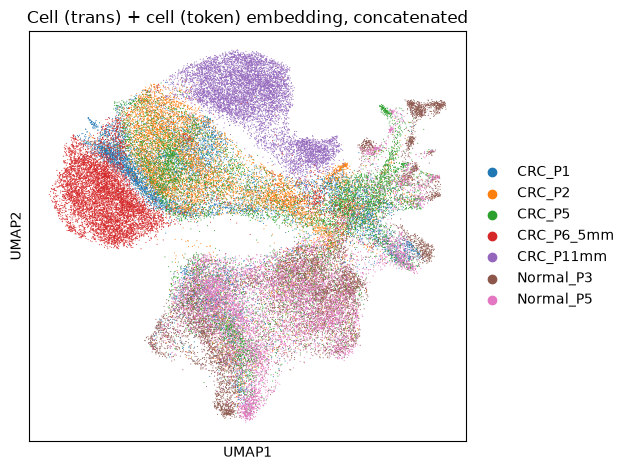

In [4]:
import h5py

TOKEN_RUN_PATH = basedir / "combined/03_integration/autoencoders/002um/with_tokens/trans_with_dae_latents.h5ad"
MAX_CELLS_PER_SLIDE = 8000
RANDOM_SEED = 0

# Selective h5py load -- see markdown above for why (RAM). sample_idx must stay
# sorted: h5py's fancy indexing on a Dataset requires increasing order.
with h5py.File(TOKEN_RUN_PATH, "r") as f:
    slide_cats = f["obs/Slide_ID/categories"].asstr()[:]
    slide_codes = f["obs/Slide_ID/codes"][:]

    rng = np.random.default_rng(RANDOM_SEED)
    sample_idx = []
    for code in range(len(slide_cats)):
        idx = np.nonzero(slide_codes == code)[0]
        if len(idx) > MAX_CELLS_PER_SLIDE:
            idx = rng.choice(idx, size=MAX_CELLS_PER_SLIDE, replace=False)
        sample_idx.append(idx)
    sample_idx = np.sort(np.concatenate(sample_idx))

    trans_cell = f["obsm/X_dae_trans_cell"][sample_idx]
    token_cell = f["obsm/X_dae_token_cell"][sample_idx]

slide_id = pd.Categorical.from_codes(slide_codes[sample_idx], categories=slide_cats)
print(f"Loaded {len(sample_idx)} cells (of {len(slide_codes)} total) across {len(slide_cats)} slides")
print(pd.Series(slide_id).value_counts())

# concatenate trans (cell-level transcriptomics) + token (cell-level histology) --
# NOT the precomputed X_dae_trans_token_hist_concat, which also folds in
# X_dae_hist_patch (the untrained patch-level branch, see markdown above)
concat_emb = np.concatenate([trans_cell, token_cell], axis=1).astype(np.float32)

emb_adata = ad.AnnData(X=concat_emb, obs=pd.DataFrame({"Slide_ID": slide_id}))
sc.pp.neighbors(emb_adata, use_rep="X")
sc.tl.umap(emb_adata)

sc.pl.umap(emb_adata, color="Slide_ID", title="Cell (trans) + cell (token) embedding, concatenated", show=False)
plt.tight_layout()
plt.show()

### Leiden clusters + dominant (marker) genes on the same UMAP

`Slide_ID` came out completely mixed above (no batch-driven separation) -- clusters the trans+token embedding and finds each cluster's top marker gene, restricted to the SVG panel (`trans_enc`'s actual 385-gene input: the union of `varm["spatially_variable_per_sample"]` across all 7 samples; not `var["spatially_variable"]`, a stale 143-gene column from an earlier merge). Reads only the `sample_idx` rows and SVG columns directly off disk (`anndata.io.sparse_dataset`), never materializing the full (1,193,045 x 18,085) matrix.

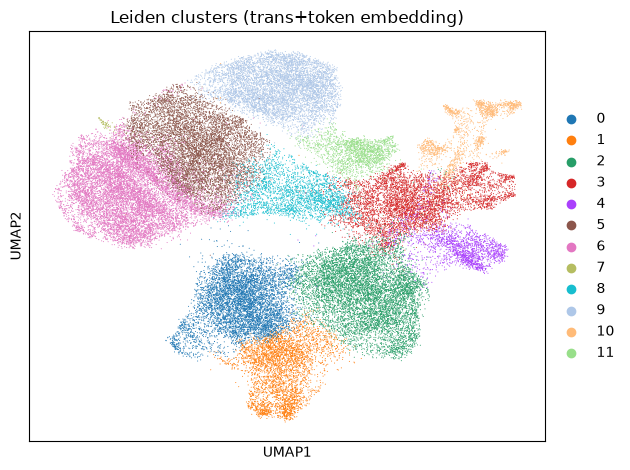

SVG union: 385 genes
Top marker gene per cluster (SVG panel): ['PIGR', 'SLC26A3', 'JCHAIN', 'COL3A1', 'TMSB4X', 'MT-ATP6', 'MT-ND4L', 'CTNNA2', 'OLFM4', 'TAGLN', 'COL1A1']


/tmp/ipykernel_117578/3135496891.py:32: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


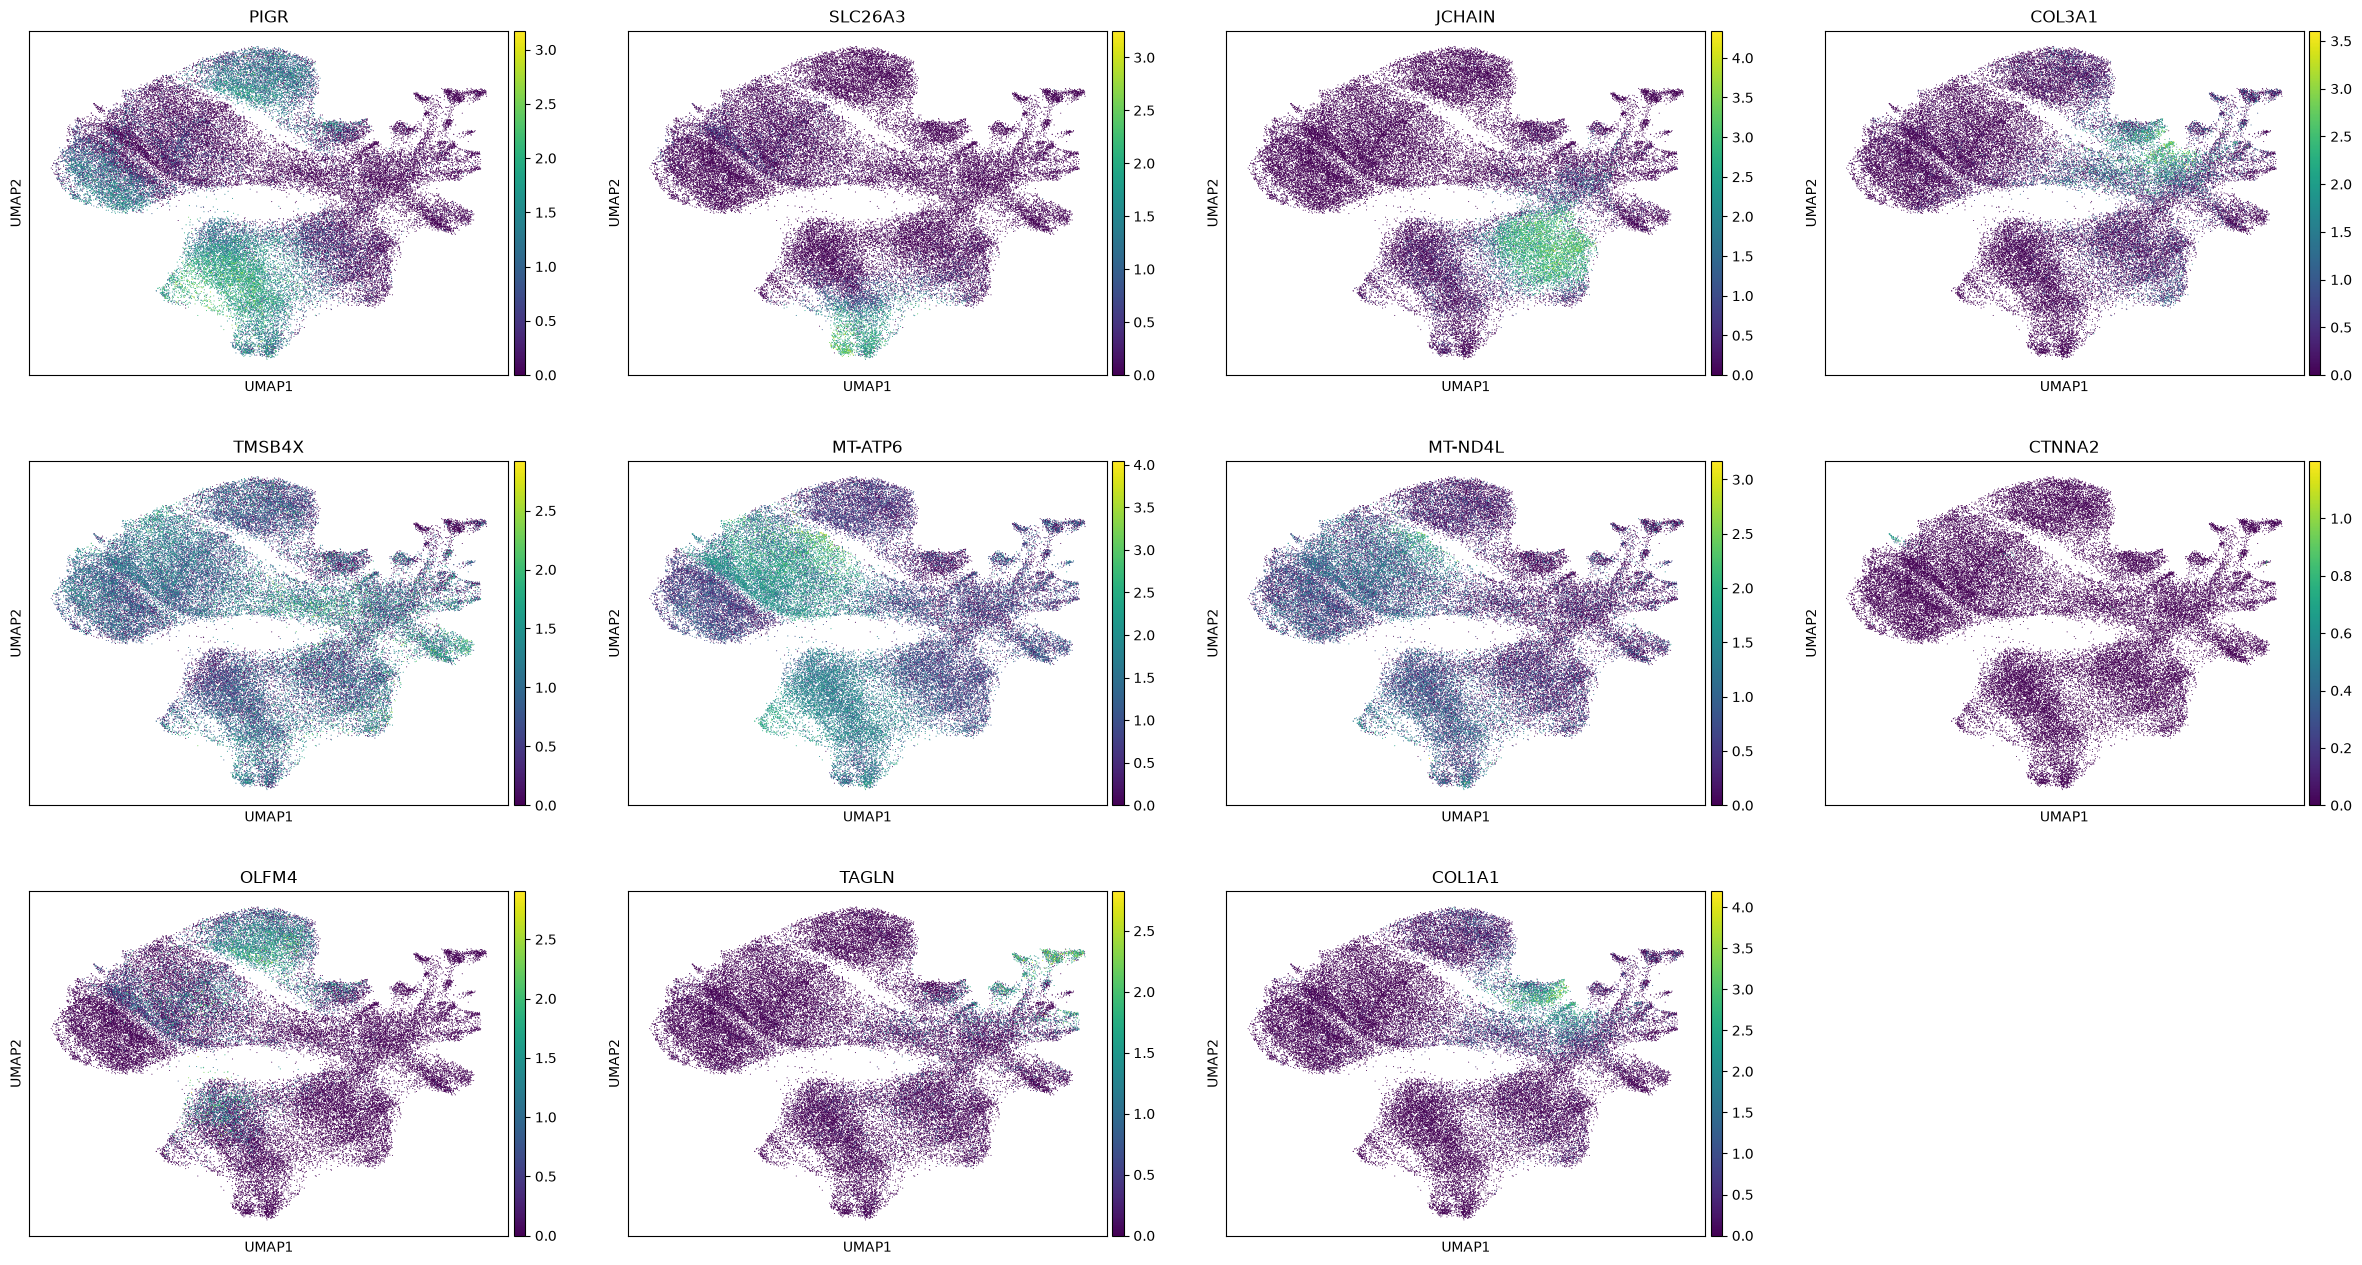

In [5]:
from anndata.io import sparse_dataset

# 1. Leiden on the neighbors graph already computed on the trans+token embedding
# (previous cell) -- needed for the marker-gene panel below and the spatial plot after.
sc.tl.leiden(emb_adata, resolution=0.5, key_added="leiden", flavor="igraph", n_iterations=2, directed=False)
sc.pl.umap(emb_adata, color="leiden", title="Leiden clusters (trans+token embedding)", show=False)
plt.tight_layout()
plt.show()

# 2. Marker genes per cluster, SVG panel only (see markdown above). sparse_dataset wraps
# the on-disk CSR group directly -- row-indexes by sample_idx, then column-indexes to the
# SVG mask, without loading the full matrix.
with h5py.File(TOKEN_RUN_PATH, "r") as f:
    svg_mask = f["varm/spatially_variable_per_sample"][:].astype(bool).any(axis=1)
    gene_names = f["var/_index"].asstr()[:][svg_mask]
    X_svg_sub = sparse_dataset(f["X"])[sample_idx][:, svg_mask]
print(f"SVG union: {svg_mask.sum()} genes")

# X is already log1p-normalized -- do NOT re-run sc.pp.log1p (would double-transform it).
svg_adata = ad.AnnData(X=X_svg_sub.tocsr(), var=pd.DataFrame(index=gene_names))
svg_adata.obs["leiden"] = emb_adata.obs["leiden"].values
svg_adata.obsm["X_umap"] = emb_adata.obsm["X_umap"]

sc.tl.rank_genes_groups(svg_adata, groupby="leiden", method="wilcoxon")
top_genes = []
for cl in svg_adata.obs["leiden"].cat.categories:
    top_genes.append(svg_adata.uns["rank_genes_groups"]["names"][cl][0])
top_genes = list(dict.fromkeys(top_genes))  # dedup, preserve order (clusters can share a top gene)
print("Top marker gene per cluster (SVG panel):", top_genes)

sc.pl.umap(svg_adata, color=top_genes, ncols=4, show=False)
plt.tight_layout()
plt.show()

### Same, but ALL cells of one slide (not the subsample)

Loads every `X_dae_trans_cell`/`X_dae_token_cell`/`spatial` row for `PLOT_SLIDE_FULL` and runs leiden directly on the full population -- no subsample, no KNN extension from the smaller reference (that shortcut was dropped: it can manufacture geometric-looking artifacts when projected onto physical space).

CRC_P1: 59178 cells -- clustering directly (no subsample/KNN extension)


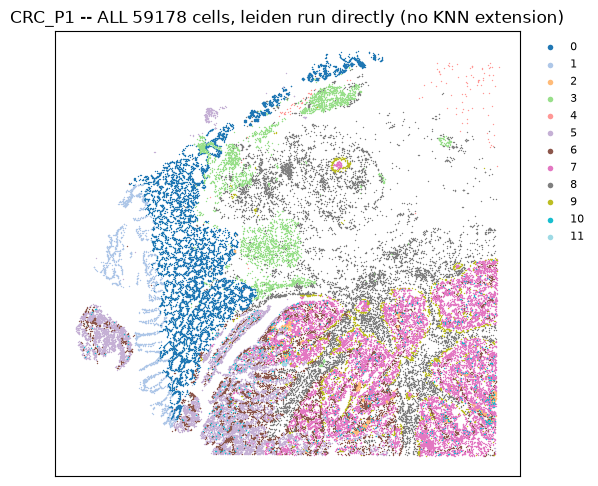

In [7]:
PLOT_SLIDE_FULL = "CRC_P1"  # change to inspect a different slide

with h5py.File(TOKEN_RUN_PATH, "r") as f:
    target_code = int(np.nonzero(slide_cats == PLOT_SLIDE_FULL)[0][0])
    full_idx = np.nonzero(slide_codes == target_code)[0]  # np.nonzero already returns ascending order
    trans_full = f["obsm/X_dae_trans_cell"][full_idx]
    token_full = f["obsm/X_dae_token_cell"][full_idx]
    spatial_full = f["obsm/spatial"][full_idx]

X_full = np.concatenate([trans_full, token_full], axis=1).astype(np.float32)
print(f"{PLOT_SLIDE_FULL}: {len(full_idx)} cells -- clustering directly (no subsample/KNN extension)")

# Leiden directly on the full slide, not a KNN-extended subsample -- extension from a
# sparse reference set can manufacture geometric-looking (Voronoi-like) boundaries when
# projected onto physical space, so this isolates whether the striping is real or an artifact.
full_adata_combined = ad.AnnData(X=X_full, obs=pd.DataFrame(index=np.arange(len(full_idx)).astype(str)))
sc.pp.neighbors(full_adata_combined, use_rep="X")
sc.tl.leiden(full_adata_combined, resolution=0.5, key_added="leiden", flavor="igraph", n_iterations=2, directed=False)
full_adata_combined.obsm["spatial"] = spatial_full

pl.plot_spatial_labels(
    full_adata_combined,
    spatial_key="spatial",
    label_key="leiden",
    mode="bin",
    point_size=1,
    title=f"{PLOT_SLIDE_FULL} -- ALL {len(full_idx)} cells, leiden run directly (no KNN extension)",
)
plt.show()

### Single-modality diagnostic: trans-only vs. token-only clustering

Same "full-slide direct leiden" approach as above, but using only one modality's embedding at a time, to see which branch the fine-scale speckle pattern is coming from. Reuses `sample_idx`/`slide_id`/`trans_cell`/`token_cell`/`slide_cats`/`slide_codes` and `PLOT_SLIDE_FULL` from the cells above.

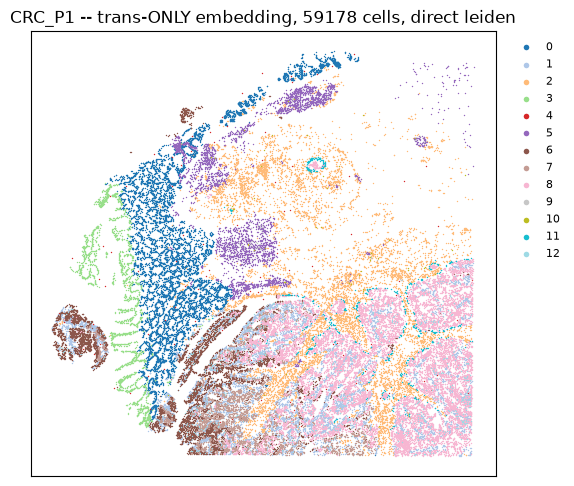

In [8]:
# trans-only: cluster on X_dae_trans_cell alone (no token)
with h5py.File(TOKEN_RUN_PATH, "r") as f:
    target_code = int(np.nonzero(slide_cats == PLOT_SLIDE_FULL)[0][0])
    full_idx = np.nonzero(slide_codes == target_code)[0]
    trans_full = f["obsm/X_dae_trans_cell"][full_idx].astype(np.float32)
    spatial_full = f["obsm/spatial"][full_idx]

full_adata_trans = ad.AnnData(X=trans_full, obs=pd.DataFrame(index=np.arange(len(full_idx)).astype(str)))
sc.pp.neighbors(full_adata_trans, use_rep="X")
sc.tl.leiden(full_adata_trans, resolution=0.5, key_added="leiden", flavor="igraph", n_iterations=2, directed=False)
full_adata_trans.obsm["spatial"] = spatial_full

pl.plot_spatial_labels(
    full_adata_trans,
    spatial_key="spatial",
    label_key="leiden",
    mode="bin",
    point_size=1,
    title=f"{PLOT_SLIDE_FULL} -- trans-ONLY embedding, {len(full_idx)} cells, direct leiden",
)
plt.show()

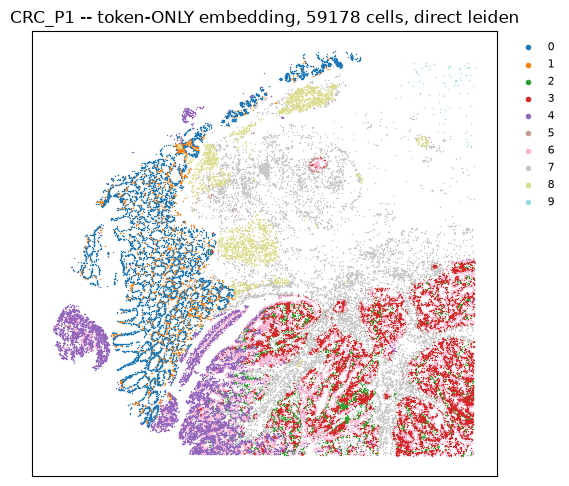

In [10]:
# token-only: cluster on X_dae_token_cell alone (no trans)
with h5py.File(TOKEN_RUN_PATH, "r") as f:
    target_code = int(np.nonzero(slide_cats == PLOT_SLIDE_FULL)[0][0])
    full_idx = np.nonzero(slide_codes == target_code)[0]
    token_full = f["obsm/X_dae_token_cell"][full_idx].astype(np.float32)
    spatial_full = f["obsm/spatial"][full_idx]

full_adata_token = ad.AnnData(X=token_full, obs=pd.DataFrame(index=np.arange(len(full_idx)).astype(str)))
sc.pp.neighbors(full_adata_token, use_rep="X")
sc.tl.leiden(full_adata_token, resolution=0.5, key_added="leiden", flavor="igraph", n_iterations=2, directed=False)
full_adata_token.obsm["spatial"] = spatial_full

pl.plot_spatial_labels(
    full_adata_token,
    spatial_key="spatial",
    label_key="leiden",
    mode="bin",
    point_size=1,
    title=f"{PLOT_SLIDE_FULL} -- token-ONLY embedding, {len(full_idx)} cells, direct leiden",
)
plt.show()

### Same slide, three feature sources side by side

Token-only, trans-only ("cells"), and the combined trans+token clustering for `PLOT_SLIDE_FULL`, reusing the leiden results already computed in the three cells above -- nothing recomputed here.

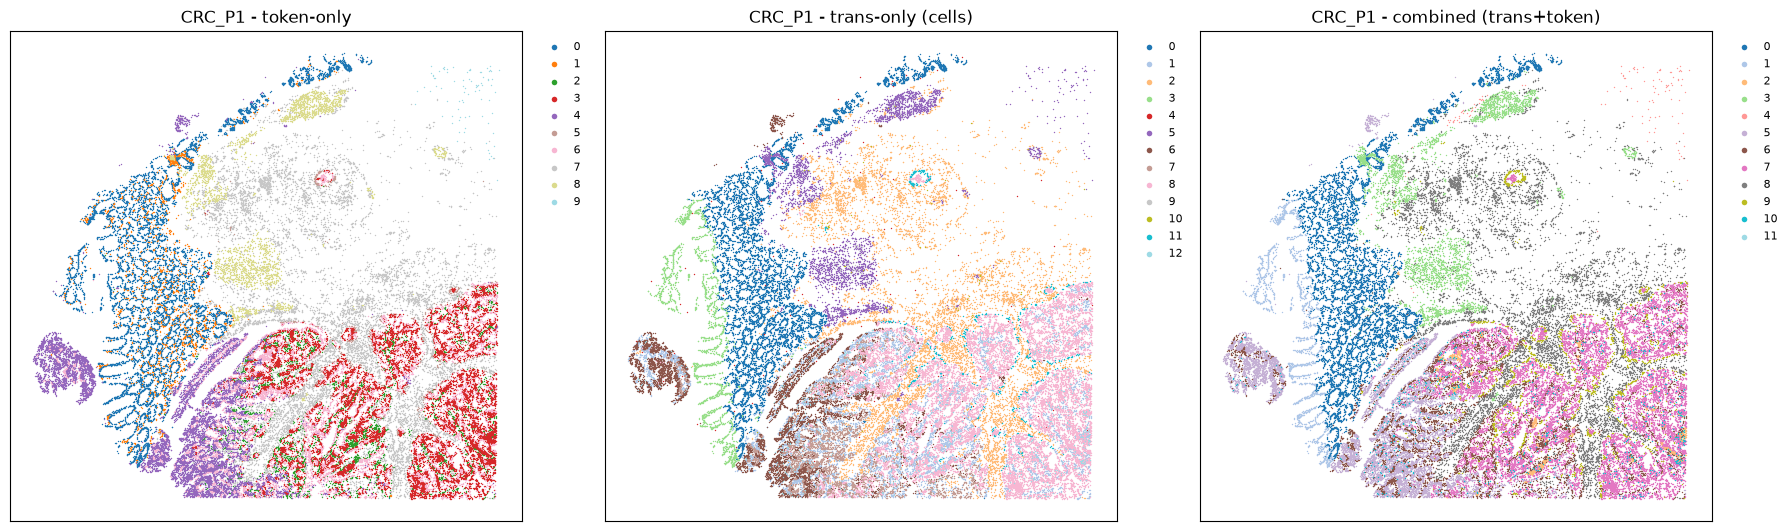

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
pl.plot_spatial_labels(
    full_adata_token, spatial_key="spatial", label_key="leiden", mode="bin", point_size=1,
    title=f"{PLOT_SLIDE_FULL} - token-only", ax=axes[0],
)
pl.plot_spatial_labels(
    full_adata_trans, spatial_key="spatial", label_key="leiden", mode="bin", point_size=1,
    title=f"{PLOT_SLIDE_FULL} - trans-only (cells)", ax=axes[1],
)
pl.plot_spatial_labels(
    full_adata_combined, spatial_key="spatial", label_key="leiden", mode="bin", point_size=1,
    title=f"{PLOT_SLIDE_FULL} - combined (trans+token)", ax=axes[2],
)
plt.tight_layout()
plt.show()

### Each slide, three feature sources, one grid per version

Same idea as the "plot all samples" grids earlier in this notebook, but here for token-only, trans-only, and combined (trans+token) clustering -- all three on the **full cell population** (all 1,193,045 cells across 7 slides), not the `sample_idx` subsample used for `emb_adata` above, so they're consistent with the full-population single-slide comparison two cells up. This is a much heavier `neighbors`/`leiden` computation than the subsample version (three separate runs at ~1.2M cells each) -- expect it to take a while.

Loaded 1193045 cells (full population) across 7 slides


/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/home/charlottewolf/miniconda3/envs/autoencoder/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


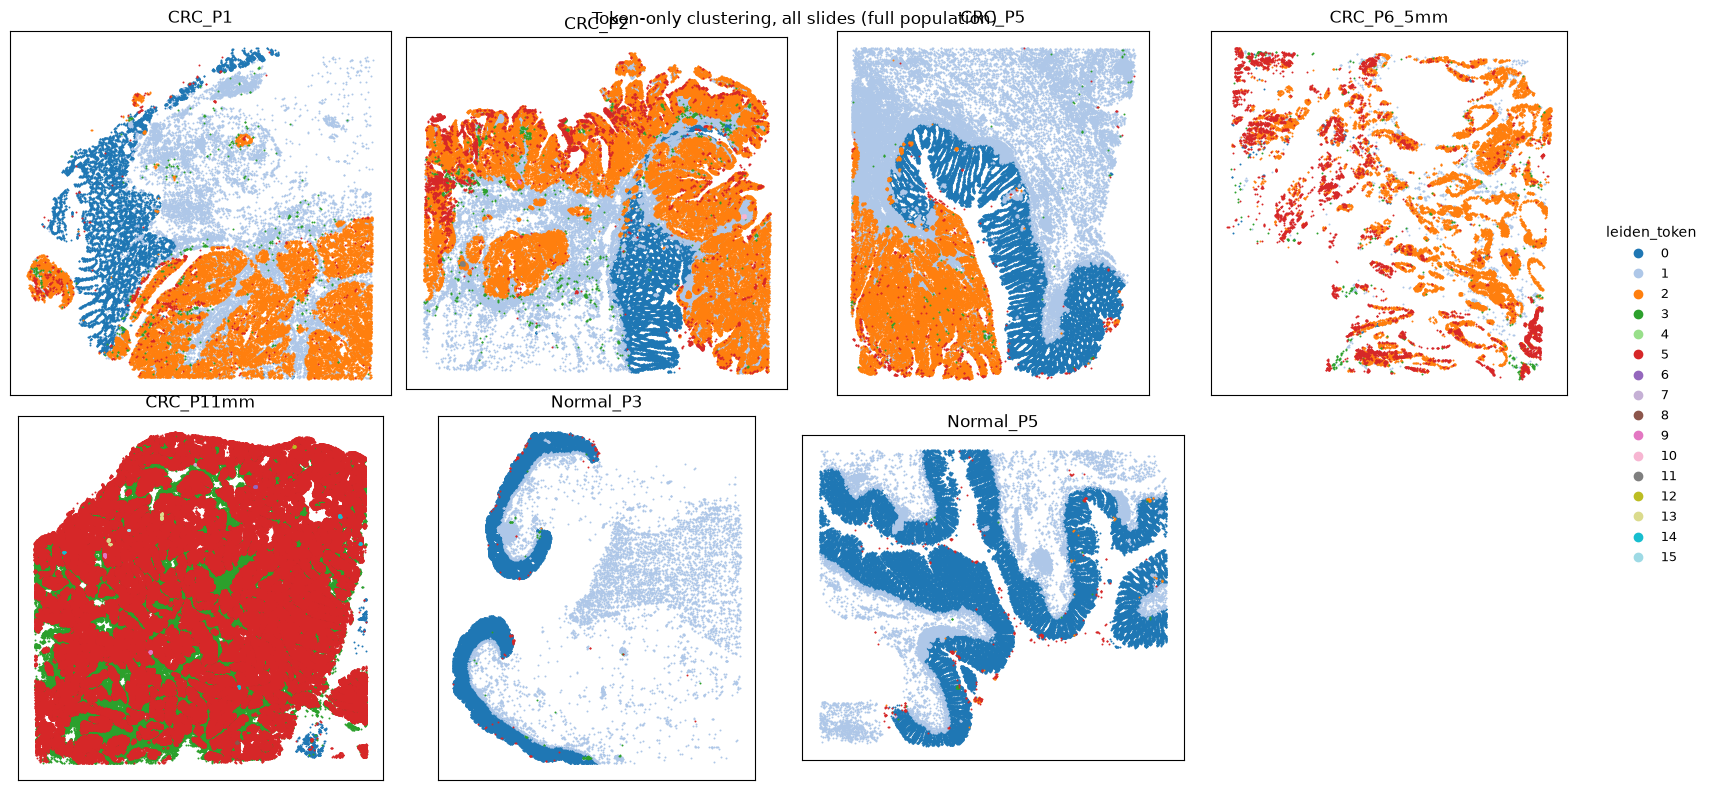

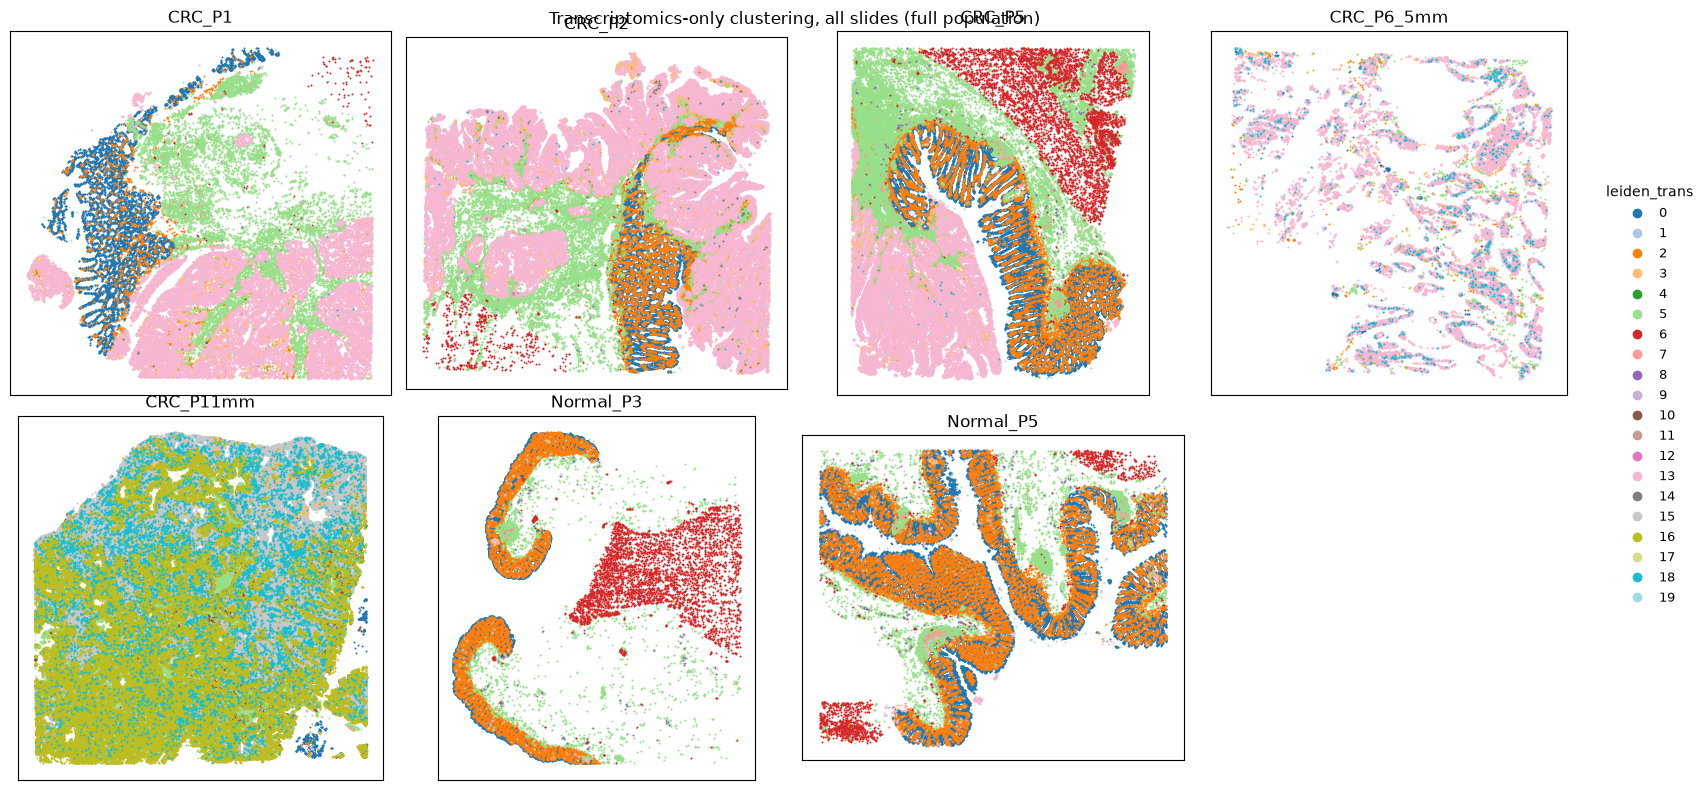

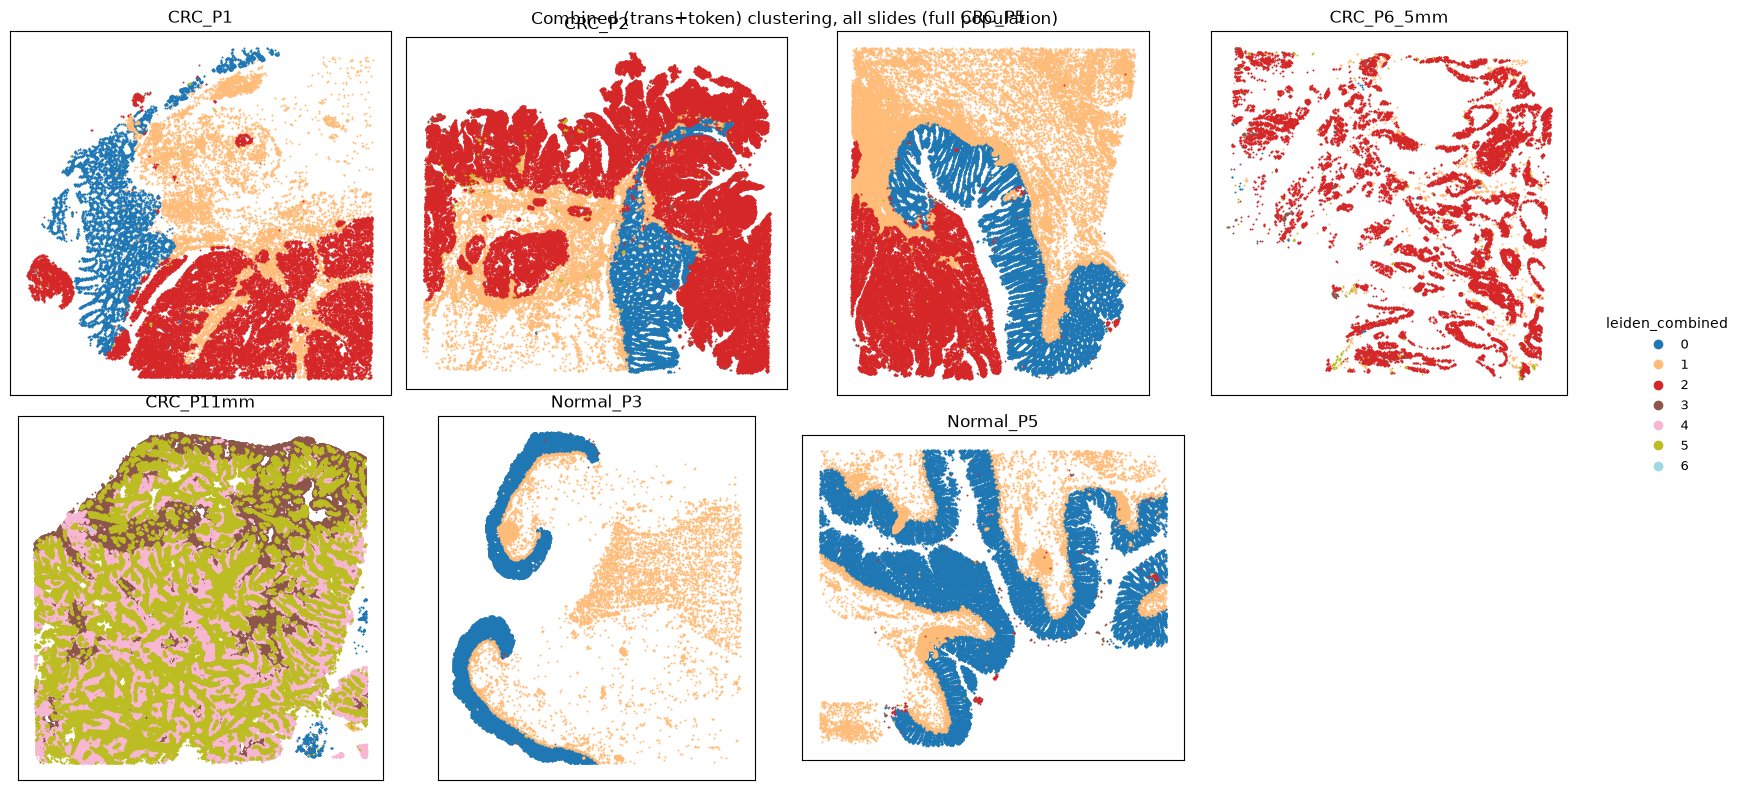

In [13]:
with h5py.File(TOKEN_RUN_PATH, "r") as f:
    slide_codes_all = f["obs/Slide_ID/codes"][:]
    slide_id_all = pd.Categorical.from_codes(slide_codes_all, categories=slide_cats)
    trans_all = f["obsm/X_dae_trans_cell"][:]
    token_all = f["obsm/X_dae_token_cell"][:]
    spatial_all = f["obsm/spatial"][:]
print(f"Loaded {len(slide_id_all)} cells (full population) across {len(slide_cats)} slides")

token_adata_all = ad.AnnData(X=token_all, obs=pd.DataFrame({"Slide_ID": slide_id_all}))
sc.pp.neighbors(token_adata_all, use_rep="X")
sc.tl.leiden(token_adata_all, resolution=0.2, key_added="leiden", flavor="igraph", n_iterations=2, directed=False)

trans_adata_all = ad.AnnData(X=trans_all, obs=pd.DataFrame({"Slide_ID": slide_id_all}))
sc.pp.neighbors(trans_adata_all, use_rep="X")
sc.tl.leiden(trans_adata_all, resolution=0.5, key_added="leiden", flavor="igraph", n_iterations=2, directed=False)

combined_all = np.concatenate([trans_all, token_all], axis=1).astype(np.float32)
combined_adata_all = ad.AnnData(X=combined_all, obs=pd.DataFrame({"Slide_ID": slide_id_all}))
sc.pp.neighbors(combined_adata_all, use_rep="X")
sc.tl.leiden(combined_adata_all, resolution=0.2, key_added="leiden", flavor="igraph", n_iterations=2, directed=False)

grid_adata = ad.AnnData(X=np.zeros((len(slide_id_all), 1)), obs=pd.DataFrame({"Slide_ID": slide_id_all}))
grid_adata.obsm["spatial"] = spatial_all
grid_adata.obs["leiden_token"] = token_adata_all.obs["leiden"].values
grid_adata.obs["leiden_trans"] = trans_adata_all.obs["leiden"].values
grid_adata.obs["leiden_combined"] = combined_adata_all.obs["leiden"].values
del token_adata_all, trans_adata_all, combined_adata_all, trans_all, token_all, combined_all
gc.collect()

for label_key, title in [
    ("leiden_token", "Token-only clustering, all slides (full population)"),
    ("leiden_trans", "Transcriptomics-only clustering, all slides (full population)"),
    ("leiden_combined", "Combined (trans+token) clustering, all slides (full population)"),
]:
    pl.plot_spatial_labels_grid(
        grid_adata, slide_key="Slide_ID", spatial_key="spatial", label_key=label_key, ncols=4, mode="bin",
    )
    plt.suptitle(title)
    plt.show()